# E239 — Preserve pretrained generalization during acquisition

**complete** · Acquisition, generalization and Pareto tests complete

2026-11-23T16:27:53+01:00 Stockholm time · ETA **—**

40/40 trained trajectories · 48 cached captures

Eight fresh A streams use 192 batch-two DINO updates under the E238 two-global/four-local crop recipe. Each arm starts from the same archived ViT-B/16 student, teacher, heads, primed center and optimizer. A paired crop draw is shared across policies within a walk. Frozen DINO defines the representation floor for A and the independent B, C and D anchors. C and D come from distinct areas of frozen descriptor space outside the A/B anchor allocation.

Consistency adds a weight-one cosine penalty against the frozen teacher on current raw A images. Last-block adaptation updates only the final block, final norm and SSL head. The adapter is a 64-wide residual bottleneck after the last block with zero output projection, and the SSL head remains trainable. Restricted arms update only trainable backbone components through teacher EMA, preserving their other teacher weights exactly. The learning-rate control halves all optimizer group rates.

The external linear probes are refit at each checkpoint using the same fit corpus. Query captures are assigned to one regime per walk, with at least 15 examples per class in each panel. The held-out generalization score averages B, C and D, and all four semantic tasks are equally weighted within each regime. Annotation metadata are restricted to evaluation. Intervals resample full walks conditional on the external probe corpus.

The primary readout is the 192-update teacher endpoint. A candidate needs at least +0.5 pp on A versus frozen and +0.5 pp on held-out regimes versus full incoming DINO, both with positive paired 95% intervals. A separate Pareto check tests whether two frontier policies each beat the other on a different axis by at least +0.25 pp, with positive paired intervals. This is a fixed-policy experiment.


## Primary effects

| Policy | A vs frozen (pp) | Held-out vs frozen (pp) | Held-out vs full (pp) | Gate |
| --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.193 [+0.059, +0.329] | — |
| Full incoming DINO | +0.003 [-0.369, +0.412] | -0.193 [-0.329, -0.059] | +0.000 [+0.000, +0.000] | — |
| Incoming + frozen consistency | -0.024 [-0.295, +0.275] | -0.349 [-0.471, -0.228] | -0.156 [-0.375, +0.064] | missed |
| Last block + final norm | +0.286 [+0.185, +0.395] | +0.333 [+0.295, +0.374] | +0.526 [+0.388, +0.662] | missed |
| Residual adapter | +0.000 [+0.000, +0.000] | +0.006 [+0.000, +0.018] | +0.199 [+0.068, +0.332] | missed |
| Full incoming · half LR | -0.292 [-0.638, +0.095] | -0.401 [-0.550, -0.250] | -0.208 [-0.367, -0.047] | missed |

Point-estimate Pareto frontier across 8 completed walks: Last block + final norm.

Acquisition–generalization trade-off in full adaptation: the paired intervals did not establish both directions.

No frontier pair met the prespecified reciprocal advantage criterion.

## A endpoint by task

| Policy | scene | weather | traffic light | pedestrian |
| --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming DINO | -0.325 [-0.869, +0.332] | -0.178 [-0.237, -0.090] | -0.601 [-1.285, +0.158] | +1.116 [-0.008, +2.386] |
| Incoming + frozen consistency | -0.645 [-1.233, +0.059] | -0.178 [-0.237, -0.090] | -0.609 [-1.075, -0.107] | +1.335 [+0.430, +2.357] |
| Last block + final norm | +0.466 [+0.245, +0.646] | +0.000 [+0.000, +0.000] | +0.504 [+0.110, +1.010] | +0.175 [+0.037, +0.316] |
| Residual adapter | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming · half LR | -0.583 [-1.061, -0.005] | -0.178 [-0.237, -0.090] | -0.521 [-1.318, +0.510] | +0.115 [-0.635, +1.148] |

## B endpoint by task

| Policy | scene | weather | traffic light | pedestrian |
| --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming DINO | -1.238 [-1.960, -0.478] | +0.538 [+0.000, +1.319] | -1.037 [-1.622, -0.308] | -2.250 [-2.813, -1.755] |
| Incoming + frozen consistency | -2.543 [-3.153, -1.890] | +0.523 [+0.000, +1.258] | -0.897 [-1.491, -0.177] | -2.359 [-2.997, -1.689] |
| Last block + final norm | +0.332 [+0.083, +0.567] | +0.000 [+0.000, +0.000] | +0.101 [-0.287, +0.512] | -0.394 [-0.563, -0.223] |
| Residual adapter | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming · half LR | -1.665 [-2.390, -0.934] | +0.000 [+0.000, +0.000] | -1.089 [-1.664, -0.369] | -1.806 [-2.405, -1.146] |

## C endpoint by task

| Policy | scene | weather | traffic light | pedestrian |
| --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming DINO | +1.662 [+0.891, +2.393] | +1.354 [+0.595, +2.098] | +0.639 [-0.473, +1.529] | -0.571 [-1.661, +0.539] |
| Incoming + frozen consistency | +1.060 [+0.580, +1.511] | +0.864 [+0.220, +1.683] | +0.803 [-0.069, +1.490] | -0.662 [-1.994, +0.911] |
| Last block + final norm | +0.550 [+0.201, +0.929] | +0.000 [+0.000, +0.000] | +0.935 [+0.479, +1.382] | +0.719 [+0.475, +0.967] |
| Residual adapter | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.074 [+0.000, +0.221] |
| Full incoming · half LR | +1.136 [+0.384, +1.881] | +0.832 [+0.215, +1.574] | +0.331 [-0.368, +0.890] | -0.569 [-1.258, +0.157] |

## D endpoint by task

| Policy | scene | weather | traffic light | pedestrian |
| --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming DINO | +1.249 [+0.423, +1.887] | +0.783 [+0.245, +1.551] | -0.566 [-1.278, +0.044] | -2.881 [-3.851, -1.732] |
| Incoming + frozen consistency | +1.255 [+0.305, +2.197] | +0.783 [+0.245, +1.551] | +0.027 [-0.795, +0.757] | -3.041 [-3.759, -2.374] |
| Last block + final norm | +0.761 [+0.395, +1.162] | +0.000 [+0.000, +0.000] | +0.041 [-0.564, +0.699] | +0.953 [+0.471, +1.432] |
| Residual adapter | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Full incoming · half LR | +0.537 [+0.038, +0.948] | +0.490 [+0.000, +1.225] | -0.244 [-0.770, +0.283] | -2.761 [-3.813, -1.638] |

## Plasticity and training cost

| Policy | Trainable encoder parameters | Student base relative displacement | Teacher A cosine drift | Mean B/C/D cosine drift | Training seconds |
| --- | --- | --- | --- | --- | --- |
| Frozen DINO | 0 | 0.00000 | 0.00000 | 0.00000 | 0.0 |
| Full incoming DINO | 85798656 | 0.00262 | 0.00364 | 0.00282 | 40.2 |
| Incoming + frozen consistency | 85798656 | 0.00290 | 0.00178 | 0.00124 | 52.0 |
| Last block + final norm | 7089408 | 0.00199 | 0.00045 | 0.00045 | 17.6 |
| Residual adapter | 98304 | 0.00000 | 0.00000 | 0.00000 | 16.3 |
| Full incoming · half LR | 85798656 | 0.00168 | 0.00272 | 0.00205 | 40.7 |

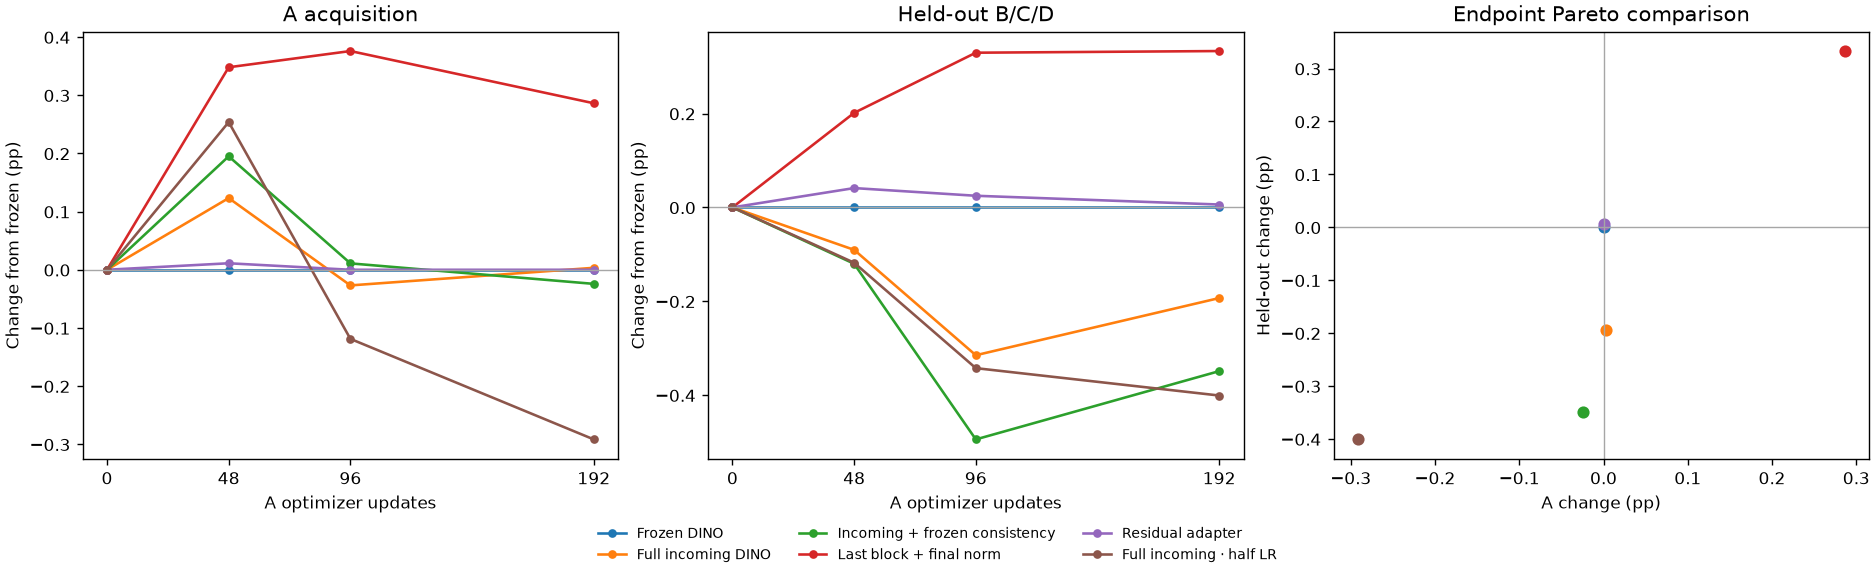